# Exercise 4


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8")
plt.rcParams.update({"image.cmap": "viridis"})

**Linear Regression**

The goal of this exercise is to explore a simple linear regression problem based on Portugese white wine.

The dataset is based on
Cortez, A. Cerdeira, F. Almeida, T. Matos and J. Reis. **Modeling wine preferences by data mining from physicochemical properties**. Published in Decision Support Systems, Elsevier, 47(4):547-553, 2009.



In [2]:
from pathlib import Path
from urllib.request import urlretrieve

data_path = Path("winequality-white.csv")
if not data_path.is_file():
    urlretrieve(
        "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv",
        data_path,
    )

**Before we start**

The downloaded file contains data on 4898 wines. For each wine 11 features are recorded (column 0 to 10). The final columns contains the quality of the wine. This is what we want to predict. More information on the features and the quality measurement is provided in the original publication.

List of columns/features:
0. fixed acidity
1. volatile acidity
2. citric acid
3. residual sugar
4. chlorides
5. free sulfur dioxide
6. total sulfur dioxide
7. density
8. pH
9. sulphates
10. alcohol
11. quality



[file]: https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv

In [3]:
# Before working with the data,
# we download and prepare all features

# load all examples from the file
data = np.genfromtxt(data_path,delimiter=";",skip_header=1)

print(f"{data.shape = }")

# Prepare for proper training
rng = np.random.default_rng(1234)
rng.shuffle(data)  # randomly sort examples

# take the first 3000 examples for training
# (remember array slicing from last week)
X_train = data[:3000, :11]  # all features except last column
y_train = data[:3000, 11]  # quality column

# and the remaining examples for testing
X_test = data[3000:, :11]  # all features except last column
y_test = data[3000:, 11]  # quality column

print("First example:")
print("Features:", X_train[0])
print("Quality:", y_train[0])

data.shape = (4898, 12)
First example:
Features: [6.8000e+00 1.9000e-01 7.1000e-01 1.7500e+01 4.2000e-02 2.1000e+01
 1.1400e+02 9.9784e-01 2.8500e+00 5.0000e-01 9.5000e+00]
Quality: 6.0


# Problems


* First we want to understand the data better. Plot (`plt.hist`) the distribution of each of the features for the training data as well as the 2D distribution (either `plt.scatter` or `plt.hist2d`) of each feature versus quality. Also calculate the correlation coefficient (`np.corrcoef`) for each feature with quality. Which feature by itself seems most predictive for the quality?

* Calculate the linear regression weights. Numpy provides functions for matrix multiplication (`np.matmul`), matrix transposition (`.T`) and matrix inversion (`np.linalg.inv`).

* Use the weights to predict the quality for the test dataset. How
does your predicted quality compare with the true quality of the test data? Calculate the correlation coefficient between predicted and true quality and draw a scatter plot.

Alcohol has the strongest linear association with quality (r = +0.429).


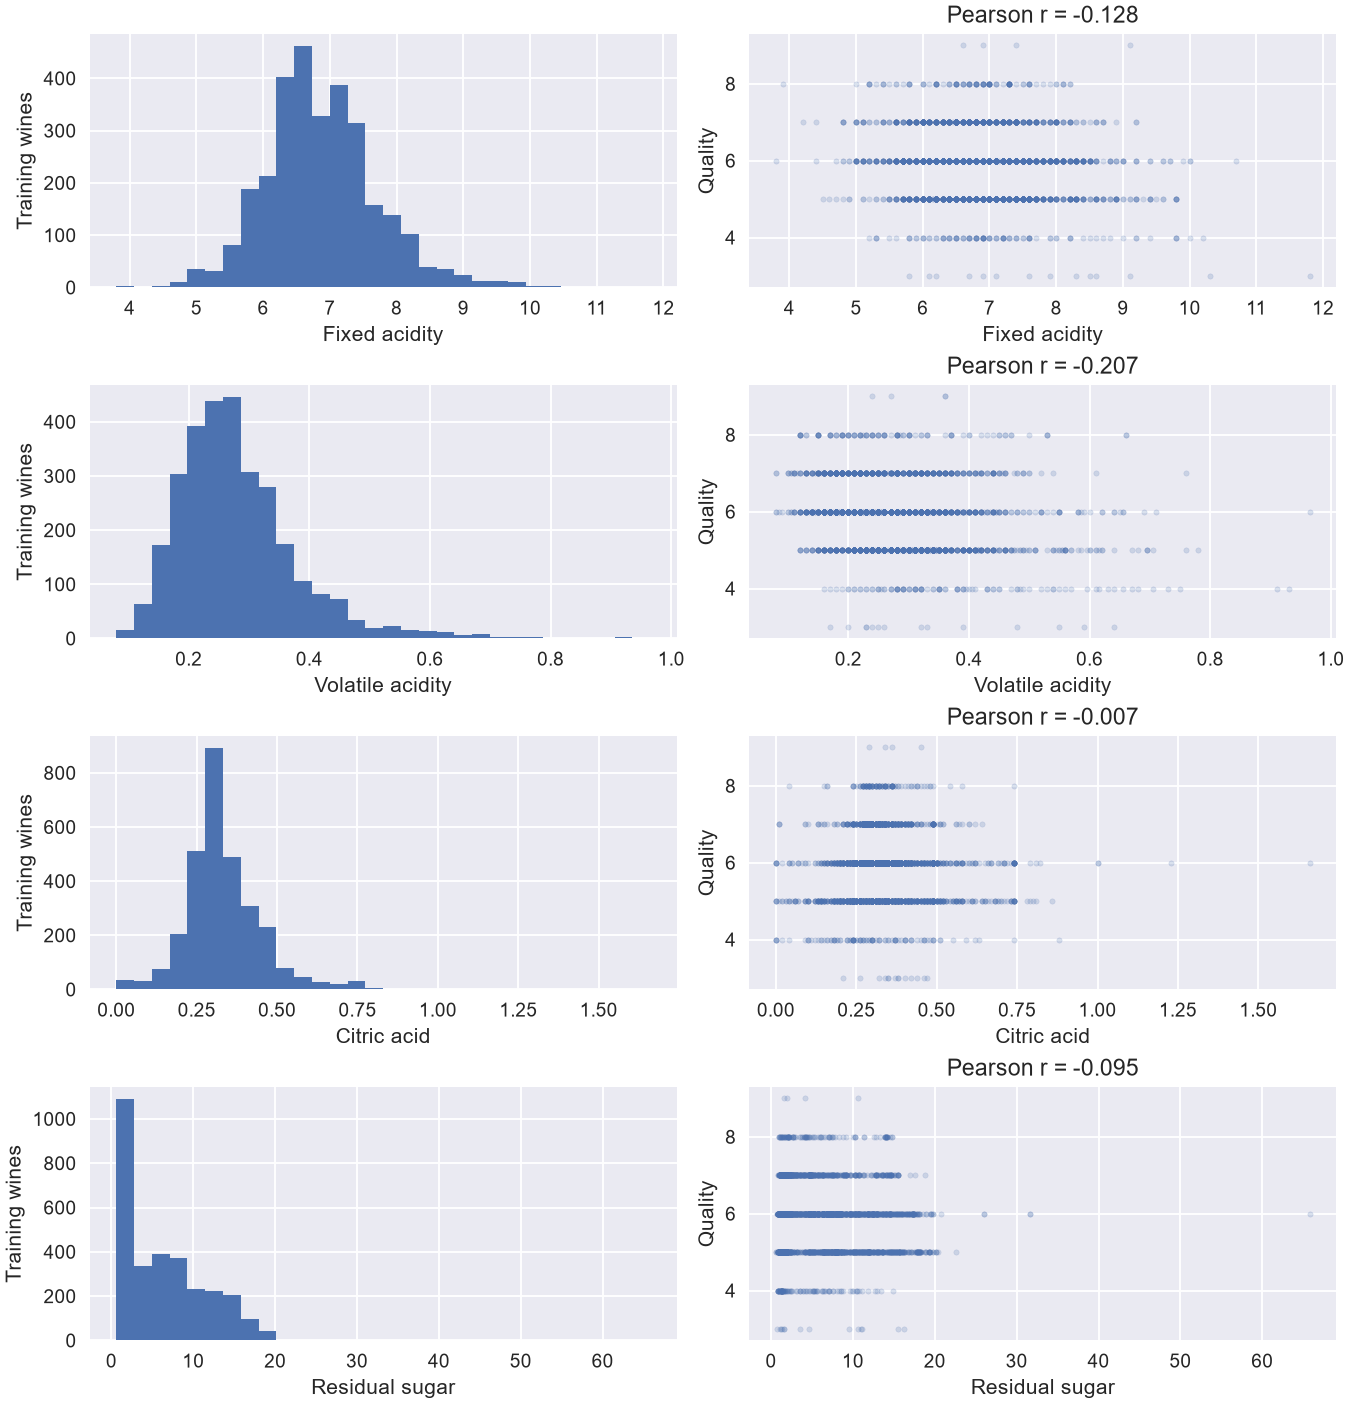

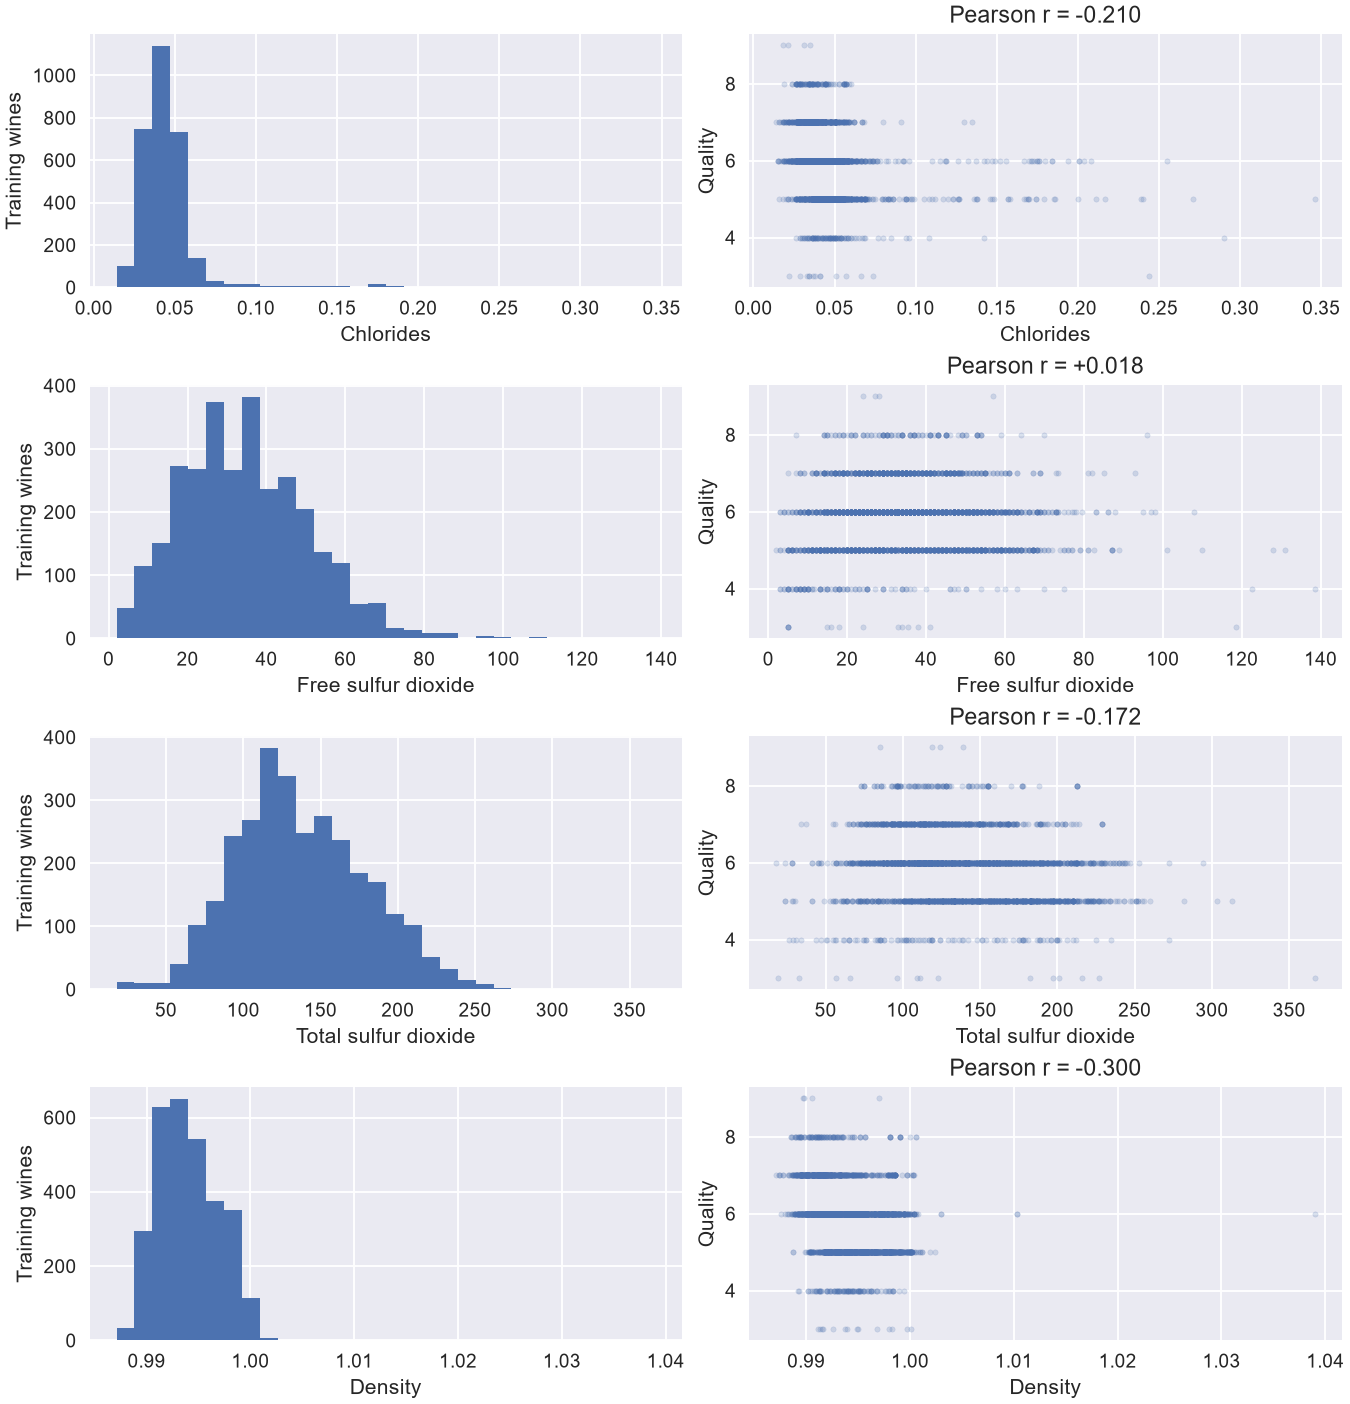

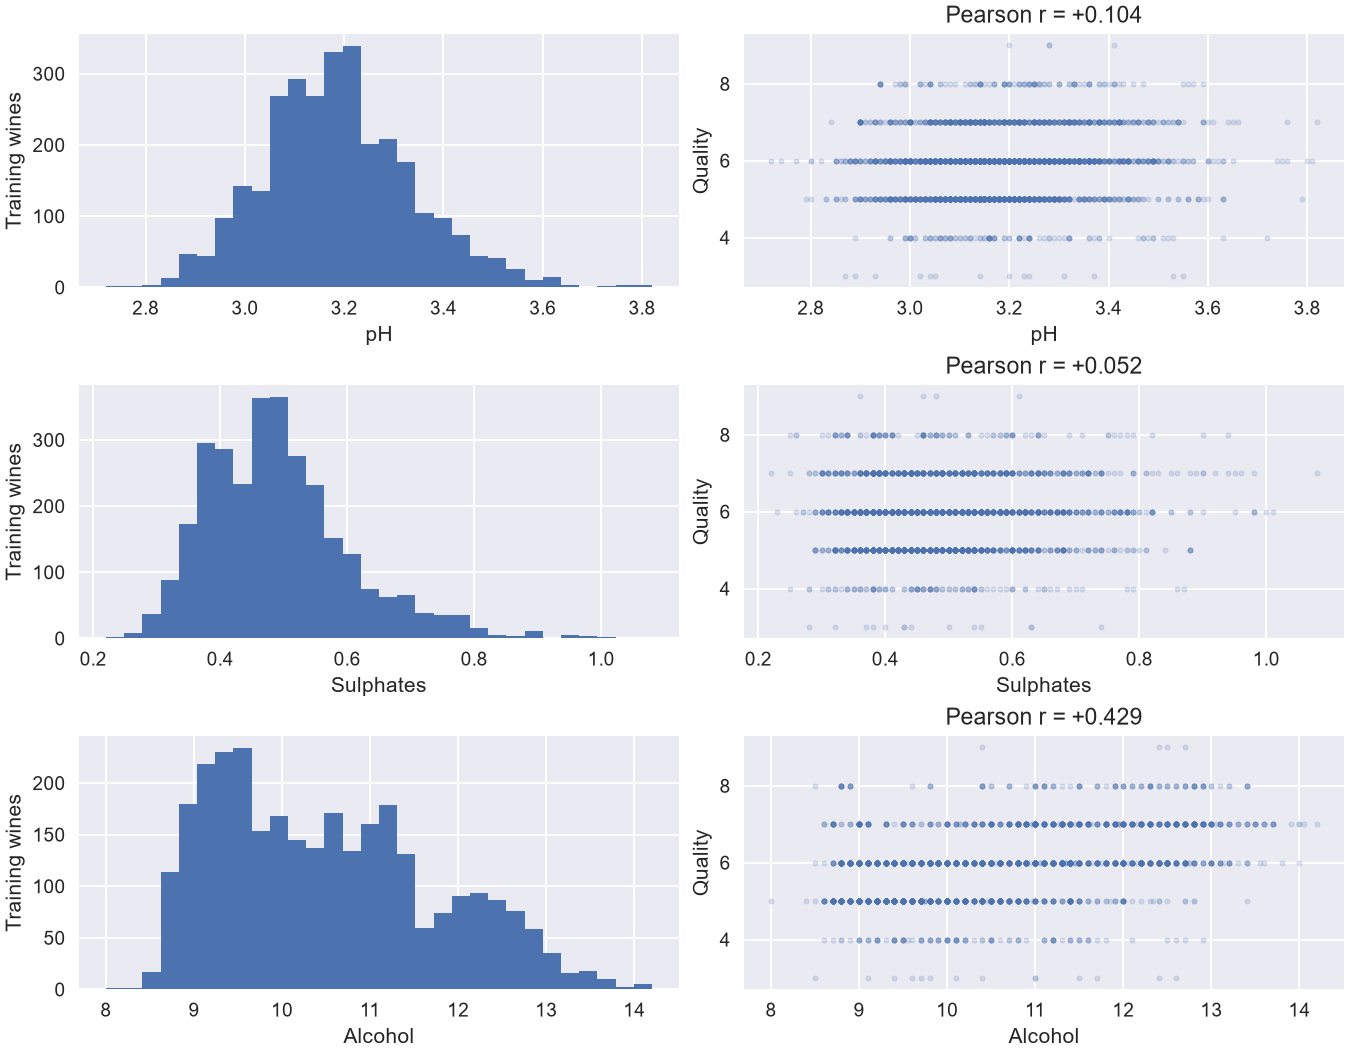

In [4]:
# 1. Explore the training features in the same order as the CSV columns.
feature_names = [
    "Fixed acidity", "Volatile acidity", "Citric acid", "Residual sugar",
    "Chlorides", "Free sulfur dioxide", "Total sulfur dioxide", "Density",
    "pH", "Sulphates", "Alcohol",
]

# [0, 1] selects the feature–quality entry from the 2×2 correlation matrix.
correlations = np.zeros(len(feature_names))
for i in range(len(feature_names)):
    correlations[i] = np.corrcoef(X_train[:, i], y_train)[0, 1]

# Use up to four rows per figure so the plots stay readable.
for start in range(0, len(feature_names), 4):
    indices = range(start, min(start + 4, len(feature_names)))
    fig, axes = plt.subplots(
        len(indices), 2, figsize=(10, 2.6 * len(indices)),
        squeeze=False, layout="constrained",
    )
    # Pair each feature's histogram with a scatter plot against quality.
    for i, (hist_ax, scatter_ax) in zip(indices, axes):
        feature = X_train[:, i]
        name = feature_names[i]
        hist_ax.hist(feature, bins=30)
        hist_ax.set(xlabel=name, ylabel="Training wines")
        scatter_ax.scatter(feature, y_train, s=8, alpha=0.2)
        scatter_ax.set(xlabel=name, ylabel="Quality", title=f"Pearson r = {correlations[i]:+.3f}")
    plt.show()

# Rank by absolute correlation so negative relationships count too.
best = np.argmax(np.abs(correlations))
print(f"{feature_names[best]} has the strongest linear association with quality "
      f"(r = {correlations[best]:+.3f}).")

In [5]:
# 2. Solve (X.T @ X) w = X.T @ y directly, using one weight per feature.
A = X_train.T @ X_train
b = X_train.T @ y_train
weights = np.linalg.solve(A, b)
for name, weight in zip(feature_names, weights):
    print(f"{name:<21} {weight:+.6f}")

Fixed acidity         -0.068702
Volatile acidity      -2.058863
Citric acid           -0.029025
Residual sugar        +0.021821
Chlorides             -1.105293
Free sulfur dioxide   +0.006030
Total sulfur dioxide  -0.001009
Density               +2.419861
pH                    +0.140579
Sulphates             +0.351125
Alcohol               +0.357608


Test Pearson r: 0.516
Test RMSE: 0.753 quality points


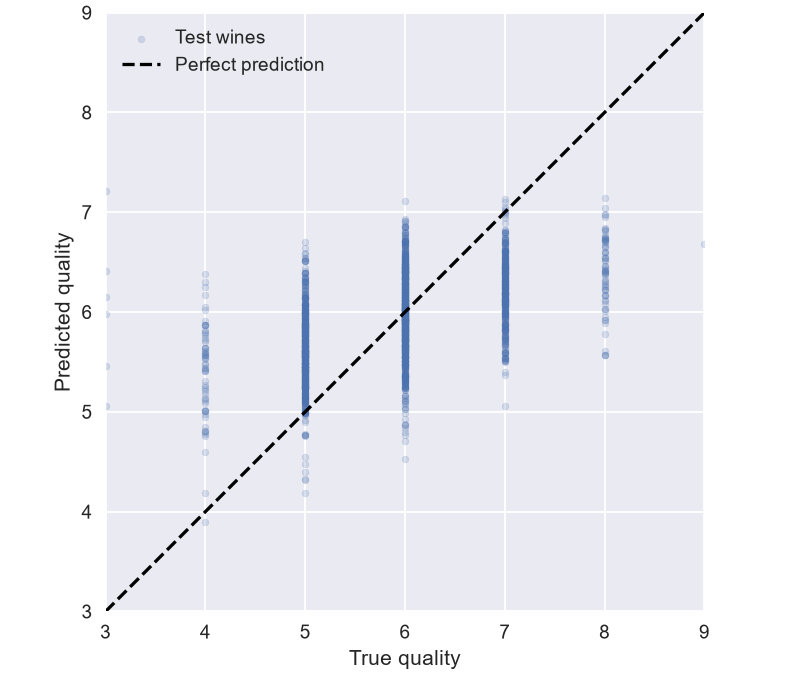

In [6]:
# 3. Use the fitted weights to make one prediction per test wine.
y_pred = X_test @ weights
test_correlation = np.corrcoef(y_pred, y_test)[0, 1]
# RMSE measures prediction error in the original quality-score units.
error = y_pred - y_test
rmse = np.sqrt(np.mean(error**2))
print(f"Test Pearson r: {test_correlation:.3f}")
print(f"Test RMSE: {rmse:.3f} quality points")

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
ax.scatter(y_test, y_pred, s=13, alpha=0.2, label="Test wines")
# Use matching axes so the diagonal shows perfect agreement.
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax.plot(limits, limits, "--", color="black", label="Perfect prediction")
ax.set(xlabel="True quality", ylabel="Predicted quality",
       xticks=np.unique(y_test), xlim=limits, ylim=limits, aspect="equal")
ax.legend()
plt.show()

# Conclusion: Alcohol had the strongest training correlation (r = 0.429).
# On the test set, the model reached r = 0.516 and RMSE = 0.753 quality points.
# Predictions clustered near 6, with low scores overestimated and high scores underestimated.

**Homework Submission**

When you submit your exercise sheet, please alwasy do two things

1) Generate a PDF of your iPython notebook. Submit this PDF through Studium (Uppsala)/Moodle (Dortmund).

2) Provide a link to your google colab notebook so that we can directly execute and test your code. To do that click on "share", change access to "anyone with the link", copy the link and add it as a comment to your submission on Studium (Uppsala)/Moodle (Dortmund).

# Hints

Formally, we want to find weights $w_i$ that minimize:
$$
\sum_{j}\left(\sum_{i} X_{i j} w_{i}-y_{j}\right)^{2}
$$
The index $i$ denotes the different features (properties of the wines) while the index $j$ runs over the different wines. The matrix $X_{ij}$ contains the training data, $y_j$ is the 'true' quality for sample $j$. The weights can be found by taking the first derivative of the above expression with respect to the weights and setting it to zero (the standard strategy for finding an extremum), and solving the corresponding system of equations (for a detailed derivation, see [here](https://en.wikipedia.org/wiki/Ordinary_least_squares)). The result is:
$$
\overrightarrow{\mathbf{w}}=\left(\mathbf{X}^{T} \mathbf{X}\right)^{-1} \mathbf{X}^{T} \overrightarrow{\mathbf{y}}
$$

In the end, you should have as many components of $w_i$ as there are features in the data (i.e. eleven in this case).

You can use `.shape` to inspect the dimensions of numpy tensors.
